# QEAIT — Algorithmic probability & CTM via **Quantum Counting** (quantum advantage)

A second QPULBA application demonstrator, following:

> A. Sarkar, Z. Al-Ars, K. Bertels, *Estimating Algorithmic Information Using Quantum Computing for
> Genomics Applications*, **Appl. Sci. 2021, 11, 2696** (Sec. 3.3.4, 4.2, Algorithm 1).

**Which application?** Of the five conditioning cases (Sec. 3.3), the one with a *provable* quantum
advantage that is not just a sampling win is **"finding the algorithmic probability of a specific
output"** — the **(B\|B\*)** branch of the Fig. 11 framework, powered by **quantum counting**.

**The metric.** For a runtime-bounded automaton the *algorithmic probability* of a string $s$ is the
fraction of programs that output it,
$$D(s) = \frac{\#\{p : U(p)=s\}}{\#\{\text{programs}\}} = \frac{M}{N},$$
and the **coding-theorem-method** complexity is $\mathrm{CTM}(s) = -\log_2 D(s)$ (Eqs. 5–6). Estimating
$D(s)$ means **counting** how many of the $N$ programs produce $s$ — exactly the count $\texttt{num}_s$
in the paper's Algorithm 1.

**Why quantum wins.** Exact counting is **#P** (Toda's theorem: an efficient classical exact counter
would collapse the polynomial hierarchy), and the program→output map of a Turing-complete automaton is
**unstructured and computationally irreducible**, so it *cannot be dequantized* with heuristics. The
**quantum counting** algorithm (Brassard–Høyer–Tapp = Grover operator + phase estimation) estimates
$M$ to additive precision $\varepsilon$ using $O(1/\varepsilon)$ oracle queries — a **quadratic
speedup** over the $O(1/\varepsilon^2)$ of classical Monte-Carlo sampling, and it never enumerates all
$N$ programs.

Below we build a compact, fully-simulable QPULBA-style program→output oracle, estimate $M$ (hence
$D(s)$ and $\mathrm{CTM}(s)$) by quantum counting, and **plot the quadratic advantage**: estimation
error vs. number of oracle queries.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from math import pi, sin, log2
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

import qiskit
print("qiskit", qiskit.__version__)

# --- A compact QPULBA-style instance -------------------------------------------------
# program register p = p3 p2 p1 p0  (N_PROG qubits -> N = 16 programs)
# output register  o = o1 o0         (a 2-bit output string produced by the automaton)
# The program->output map below is a small fixed reversible circuit standing in for a
# few QPULBA ticks; classically it is:  o0 = p0 XOR (p1 AND p2),  o1 = p2 AND p3.
N_PROG = 4
N_OUT = 2
N = 2 ** N_PROG
prog = list(range(N_PROG))
out = list(range(N_PROG, N_PROG + N_OUT))


def f_classical(p):
    p0 = p & 1; p1 = (p >> 1) & 1; p2 = (p >> 2) & 1; p3 = (p >> 3) & 1
    return ((p2 & p3) << 1) | (p0 ^ (p1 & p2))


# classical universal distribution (ground truth): M(s) for every output s
counts = {s: 0 for s in range(2 ** N_OUT)}
for p in range(N):
    counts[f_classical(p)] += 1

print("\nclassical universal distribution (ground truth):")
print(f"{'output s':>9} {'M (count)':>10} {'D(s)=M/N':>10} {'CTM=-log2 D':>12}")
for s, M in counts.items():
    ap = M / N
    ctm = -log2(ap) if ap > 0 else float('inf')
    print(f"{s:>09b} {M:>10} {ap:>10.4f} {ctm:>12.4f}")

qiskit 2.3.0

classical universal distribution (ground truth):
 output s  M (count)   D(s)=M/N  CTM=-log2 D
000000000          6     0.3750       1.4150
000000001          6     0.3750       1.4150
000000010          2     0.1250       3.0000
000000011          2     0.1250       3.0000


## The quantum-counting circuit

The oracle computes the automaton output $f(p)$ into ancillas, phase-flips the programs whose output
equals the target $s$, then uncomputes the ancillas — so the marked amplitude on the $N$-program
register is exactly $M/N$. The **Grover operator** $G = D\cdot O$ (oracle $O$ + diffuser $D$) rotates by
an angle $\theta$ with $\sin^2(\theta/2)=M/N$; **phase estimation** reads $\varphi=\theta/2\pi$, giving
$$M = N\sin^2(\pi\varphi).$$

In [2]:
def compute_f(qc):
    qc.cx(prog[0], out[0]); qc.ccx(prog[1], prog[2], out[0])   # o0 = p0 XOR (p1 AND p2)
    qc.ccx(prog[2], prog[3], out[1])                           # o1 = p2 AND p3


def uncompute_f(qc):
    qc.ccx(prog[2], prog[3], out[1])
    qc.ccx(prog[1], prog[2], out[0]); qc.cx(prog[0], out[0])


def oracle(qc, s):
    compute_f(qc)
    for i in range(N_OUT):
        if not (s >> i) & 1:
            qc.x(out[i])
    qc.cz(out[0], out[1])                 # phase-flip programs whose output == s
    for i in range(N_OUT):
        if not (s >> i) & 1:
            qc.x(out[i])
    uncompute_f(qc)


def diffuser(qc):
    qc.h(prog); qc.x(prog)
    qc.h(prog[-1]); qc.mcx(prog[:-1], prog[-1]); qc.h(prog[-1])
    qc.x(prog); qc.h(prog)


def grover_gate(s):
    qc = QuantumCircuit(N_PROG + N_OUT, name="G")
    oracle(qc, s)
    diffuser(qc)
    qc.global_phase += pi                 # standard Grover operator -> sin^2 readout
    return qc.to_gate()


def iqft(qc, qubits):
    n = len(qubits)
    for j in reversed(range(n)):
        for m in reversed(range(j)):
            qc.cp(-pi / 2 ** (j - m), qubits[m], qubits[j])
        qc.h(qubits[j])
    for i in range(n // 2):
        qc.swap(qubits[i], qubits[n - 1 - i])


def quantum_count(s, t):
    # t counting qubits -> Q = 2**t - 1 controlled-Grover applications
    cG = grover_gate(s).control(1)
    ev = list(range(t))
    pr = list(range(t, t + N_PROG))
    ou = list(range(t + N_PROG, t + N_PROG + N_OUT))
    qc = QuantumCircuit(t + N_PROG + N_OUT)
    qc.h(ev)
    qc.h(pr)                              # eigenstate = uniform superposition of programs
    for k in range(t):
        for _ in range(2 ** k):
            qc.append(cG, [ev[k]] + pr + ou)
    iqft(qc, ev)
    probs = Statevector(qc).probabilities(ev)
    b = int(np.argmax(probs))
    phi = b / 2 ** t
    M_est = N * sin(pi * phi) ** 2
    return M_est, phi, probs

## Estimate $M$, $D(s)$ and $\mathrm{CTM}(s)$ for a target output

We pick the target output $s = 10_2$ (true $M=2$, so $D=1/8$ and $\mathrm{CTM}=3$ bits) and watch the
quantum-counting estimate sharpen as we add counting qubits $t$ (queries $Q=2^t-1$).

In [3]:
TARGET = 2
M_true = counts[TARGET]
print(f"target s = {TARGET:02b}   true M = {M_true}   D = {M_true/N:.4f}   CTM = {-log2(M_true/N):.4f}\n")

print(f"{'t':>2} {'queries Q':>9} {'phi':>7} {'M_est':>7} {'D_est':>7} {'CTM_est':>8}")
rows = []
for t in range(3, 9):
    M_est, phi, _ = quantum_count(TARGET, t)
    d_est = max(M_est, 1e-9) / N
    rows.append((t, 2 ** t - 1, abs(M_est - M_true)))
    print(f"{t:>2} {2**t-1:>9} {phi:>7.4f} {M_est:>7.3f} {d_est:>7.4f} {-log2(d_est):>8.4f}")

target s = 10   true M = 2   D = 0.1250   CTM = 3.0000

 t queries Q     phi   M_est   D_est  CTM_est
 3         7  0.1250   2.343  0.1464   2.7716


 4        15  0.0625   0.609  0.0381   4.7156


 5        31  0.0938   1.348  0.0843   3.5689


 6        63  0.1094   1.816  0.1135   3.1393


 7       127  0.1094   1.816  0.1135   3.1393


 8       255  0.1133   1.942  0.1214   3.0422


## The quantum advantage: estimation error vs. oracle queries

We now compare, for the **same oracle**, how the estimation error of $M$ shrinks with the number of
oracle queries $Q$:

- **Quantum counting** — error $\propto 1/Q$ (Heisenberg-limited amplitude estimation).
- **Classical Monte-Carlo** — sample $Q$ random programs, estimate $\hat M = N\cdot(\text{hits}/Q)$;
  error $\propto 1/\sqrt{Q}$ (standard sampling).

On a log–log plot the two slopes ($-1$ vs $-\tfrac12$) are the **quadratic speedup**.

In [4]:
rng = np.random.default_rng(7)

# quantum counting error vs queries
q_Q, q_err = [], []
for t in range(3, 9):
    M_est, _, _ = quantum_count(TARGET, t)
    q_Q.append(2 ** t - 1)
    q_err.append(abs(M_est - M_true))

# classical Monte-Carlo error vs queries (mean |error| over many trials)
def mc_error(s, Q, trials=400):
    errs = np.empty(trials)
    for j in range(trials):
        samples = rng.integers(N, size=Q)
        hits = np.sum([f_classical(int(p)) == s for p in samples])
        errs[j] = abs(N * hits / Q - counts[s])
    return errs.mean()

c_Q = [2 ** t - 1 for t in range(3, 13)]
c_err = [mc_error(TARGET, Q) for Q in c_Q]

# phase-estimation histogram at a fixed t (shows the peak that encodes M)
_, _, probs = quantum_count(TARGET, 7)
print("prepared advantage data; peak phase bins:", int(np.argmax(probs)), "of", len(probs))

prepared advantage data; peak phase bins: 14 of 128


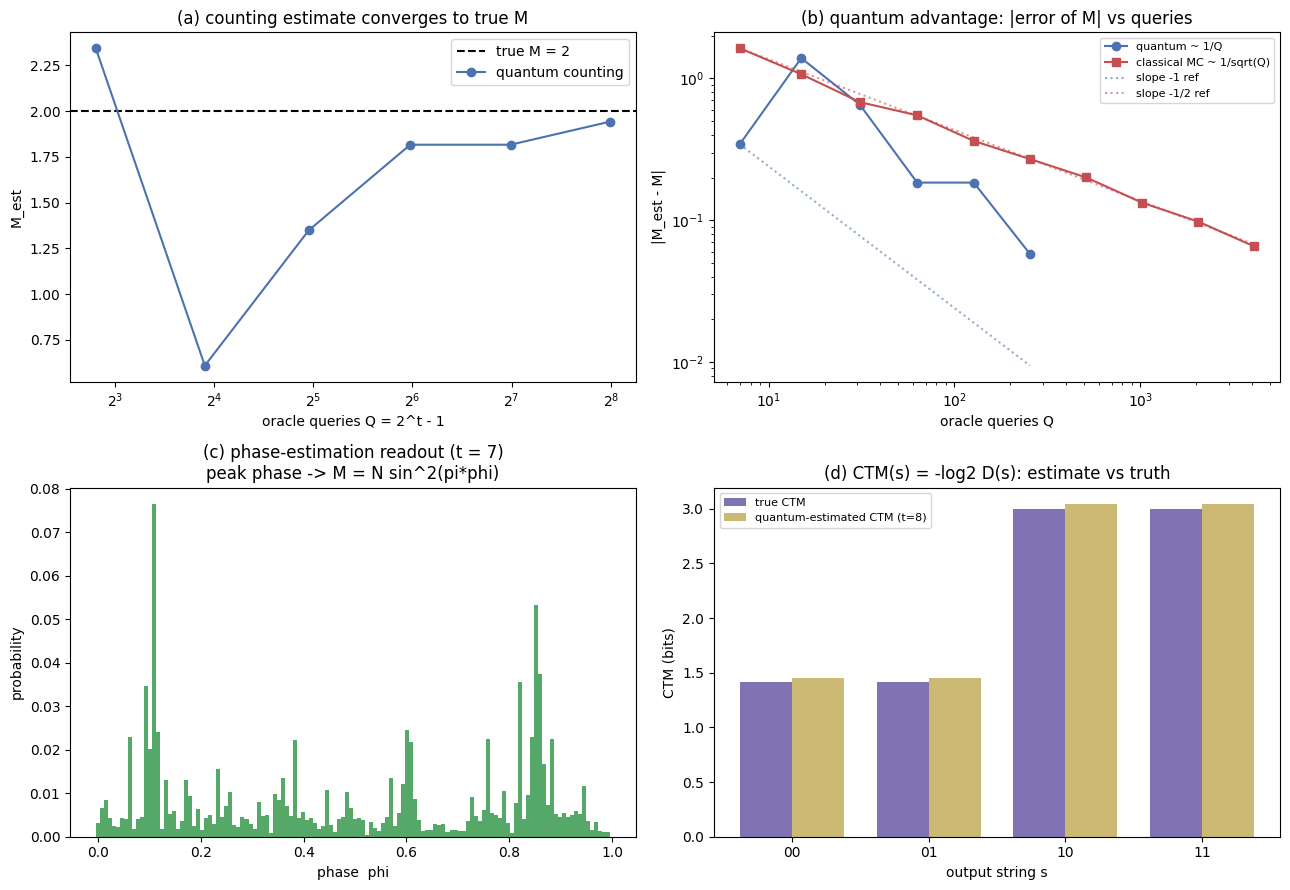

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# (a) convergence of M_est to true M
ts = list(range(3, 9))
mest = [quantum_count(TARGET, t)[0] for t in ts]
ax[0, 0].axhline(M_true, color='k', ls='--', label=f'true M = {M_true}')
ax[0, 0].plot([2 ** t - 1 for t in ts], mest, 'o-', color='#4C72B0', label='quantum counting')
ax[0, 0].set_xscale('log', base=2)
ax[0, 0].set_title('(a) counting estimate converges to true M')
ax[0, 0].set_xlabel('oracle queries Q = 2^t - 1'); ax[0, 0].set_ylabel('M_est'); ax[0, 0].legend()

# (b) THE quantum advantage: error vs queries, log-log with reference slopes
ax[0, 1].loglog(q_Q, np.maximum(q_err, 1e-3), 'o-', color='#4C72B0', label='quantum ~ 1/Q')
ax[0, 1].loglog(c_Q, c_err, 's-', color='#C44E52', label='classical MC ~ 1/sqrt(Q)')
qref = np.array(q_Q, dtype=float)
ax[0, 1].loglog(qref, q_err[0] * q_Q[0] / qref, ':', color='#4C72B0', alpha=0.6, label='slope -1 ref')
cref = np.array(c_Q, dtype=float)
ax[0, 1].loglog(cref, c_err[0] * np.sqrt(c_Q[0]) / np.sqrt(cref), ':', color='#C44E52', alpha=0.6, label='slope -1/2 ref')
ax[0, 1].set_title('(b) quantum advantage: |error of M| vs queries')
ax[0, 1].set_xlabel('oracle queries Q'); ax[0, 1].set_ylabel('|M_est - M|'); ax[0, 1].legend(fontsize=8)

# (c) phase-estimation histogram -> the peak encodes M
ax[1, 0].bar(np.arange(len(probs)) / len(probs), probs, width=1.0 / len(probs), color='#55A868')
ax[1, 0].set_title('(c) phase-estimation readout (t = 7)\npeak phase -> M = N sin^2(pi*phi)')
ax[1, 0].set_xlabel('phase  phi'); ax[1, 0].set_ylabel('probability')

# (d) estimated vs true CTM for every output string
outs = sorted(counts)
ctm_true = [-log2(counts[s] / N) for s in outs]
ctm_est = []
for s in outs:
    M_est, _, _ = quantum_count(s, 8)
    ctm_est.append(-log2(max(M_est, 1e-9) / N))
x = np.arange(len(outs)); w = 0.38
ax[1, 1].bar(x - w / 2, ctm_true, w, label='true CTM', color='#8172B3')
ax[1, 1].bar(x + w / 2, ctm_est, w, label='quantum-estimated CTM (t=8)', color='#CCB974')
ax[1, 1].set_xticks(x); ax[1, 1].set_xticklabels([format(s, '02b') for s in outs])
ax[1, 1].set_title('(d) CTM(s) = -log2 D(s): estimate vs truth')
ax[1, 1].set_xlabel('output string s'); ax[1, 1].set_ylabel('CTM (bits)'); ax[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Takeaways

- **Panel (a)** — quantum counting drives $M_{\text{est}}\to M$ as counting qubits (queries) grow.
- **Panel (b)** — the headline result: the quantum error falls as $1/Q$ while classical Monte-Carlo
  falls as $1/\sqrt{Q}$. The gap is the **quadratic speedup** of amplitude estimation, and it is exactly
  the speedup the paper's Algorithm 1 exploits for $\texttt{num}_s$ (and $\texttt{num}_h$).
- **Panels (c)/(d)** — the phase-estimation peak encodes $M$, which converts directly into
  $D(s)=M/N$ and $\mathrm{CTM}(s)=-\log_2 D(s)$, matching the classical ground truth.

**Why this is a genuine advantage (not dequantizable).** Exact counting is #P-hard (Toda), and the
QPULBA program→output relation is unstructured and computationally irreducible, so no classical
heuristic can shortcut it — the only classical routes are full enumeration ($O(N)$) or sampling
($O(1/\varepsilon^2)$). Quantum counting needs neither. Full CTM (Algorithm 1) runs the count twice —
once for programs that output $s$ ($\texttt{num}_s$) and once for programs reaching the halt state
($\texttt{num}_h$) — giving $\mathrm{CTM}(s) = -\log_2(\texttt{num}_s/\texttt{num}_h)$; here we used
$\texttt{num}_h = N$ for the runtime-bounded (non-halting) model.

**Next iteration.** Swap the toy $f$ for the genuine QPULBA-`U` builder (as in `qeait.ipynb`), scale
$N$, add the halt-state count, and replace textbook phase-estimation counting with QFT-free amplitude
estimation (refs. [43–45]) for shallower circuits.